## PHASE 2.0 - DATA UNDERSTANDING
# INGESTION, EXPLORATORY ANALYSIS, VISUALIZATION

In [10]:
#Importing Python Libaries
import pandas as pd
import numpy as np, json

In [11]:
#Loading the LendingClub data
df = pd.read_csv(r"C:\Users\moyos\Downloads\Lendingclub.csv")
print(f"Shape: {df.shape}")
df.head()

C:\Users\moyos\AppData\Local\Temp\ipykernel_18428\3982024170.py:2: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\moyos\Downloads\Lendingclub.csv")


Shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [3]:
#Performing Explorator Data Analysis for LendingClub Dataset
#Cheking data type
print(df.dtypes)

#Checking for missing values
print(df.isnull().sum())

#Checking for any strange or unique value
categorical_lc = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_lc:
    print(f"\n{col}")
    print(df[col].nunique())
    print(df[col].value_counts().head(10))

#Descrptive Statistics
print(df.describe())

#Checking for duplicate values
print(df.duplicated().sum())

#Checking for uniqueness in the id column
print(df['id'].duplicated().sum())


id                    int64
issue_d              object
revenue             float64
dti_n               float64
loan_amnt             int64
fico_n              float64
experience_c          int64
emp_length           object
purpose              object
home_ownership_n     object
addr_state           object
zip_code             object
Default               int64
title                object
desc                 object
dtype: object
id                        0
issue_d                   0
revenue                   0
dti_n                     0
loan_amnt                 0
fico_n                    0
experience_c              0
emp_length                0
purpose                   0
home_ownership_n          0
addr_state                0
zip_code                  1
Default                   0
title                 16657
desc                1228582
dtype: int64

issue_d
139
issue_d
Mar-2016    48927
Oct-2015    42986
Jul-2015    41053
Dec-2015    39001
Oct-2014    36072
Feb-2016    34597
Nov-

In [4]:
#Analyzing the Target Column in LendingClub Datatset
print(df['Default'].value_counts())
print(df['Default'].value_counts(normalize=True) * 100)

Default
0    1078432
1     269249
Name: count, dtype: int64
Default
0    80.021311
1    19.978689
Name: proportion, dtype: float64


In [5]:
#Loading the complementary dataset - Home Credit (application_train.csv)
df_HC= pd.read_csv(r"C:\Users\moyos\Downloads\HomeCredit.csv")
print(f"Shape: {df_HC.shape}")
df_HC.head()

Shape: (307511, 122)

Columns: ['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUI

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
#Performing Exploratory Data Analysis for Home Credit (application_train.csv) Dataset

#Cheking data type
print(df_HC.dtypes)

#Checking for missing values
print(df_HC.isnull().sum())

#Checking for any strange or unique value
categorical_lc = df_HC.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_lc:
    print(f"\n{col}")
    print(df_HC[col].nunique())
    print(df_HC[col].value_counts().head(10))

#Descrptive Statistics
print(df_HC.describe())

#Checking for duplicate values
print(df_HC.duplicated().sum())

#Checking for uniqueness in the id column
print(df_HC['SK_ID_CURR'].duplicated().sum())


SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE             object
CODE_GENDER                    object
FLAG_OWN_CAR                   object
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object
SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64

NAME_CONTRACT_TYPE
2
NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

CODE_GENDER
3

In [7]:
#Analyzing the Target Column in Home Credit Datatset
print(df_HC['TARGET'].value_counts())
print(df_HC['TARGET'].value_counts(normalize=True) * 100)

TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


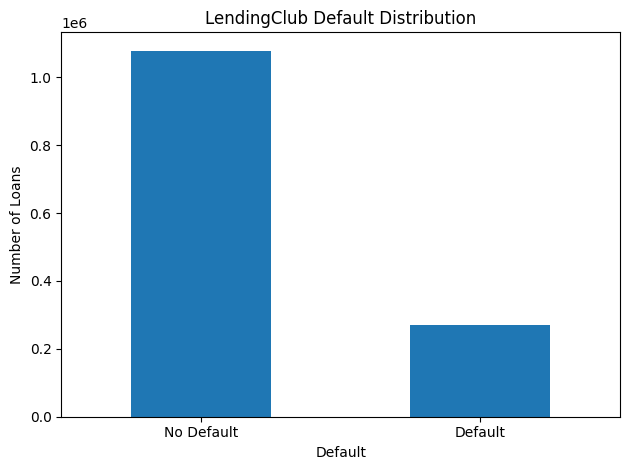

In [8]:
#Distribution Visualization - Lending Club

import matplotlib.pyplot as plt

df['Default'].value_counts().sort_index().plot(
    kind='bar'
)

plt.title('LendingClub Default Distribution')
plt.xlabel('Default')
plt.ylabel('Number of Loans')
plt.xticks(
    ticks=[0, 1],
    labels=['No Default', 'Default'],
    rotation=0
)
plt.tight_layout()
plt.show()

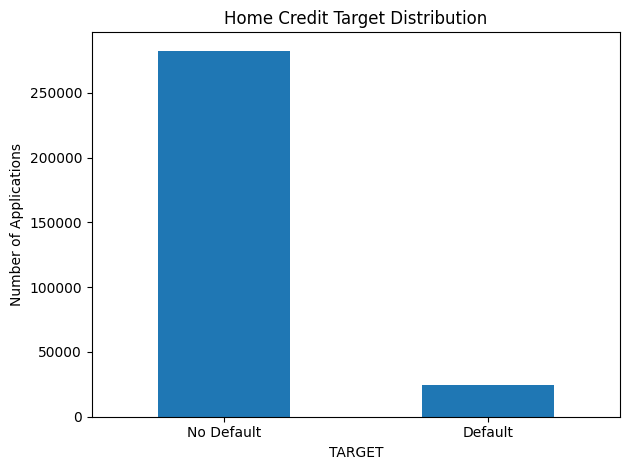

In [9]:
# Default Distribution Visualization - Home Credit (application_train.csv)

df_HC['TARGET'].value_counts().sort_index().plot(
    kind='bar'
)

plt.title('Home Credit Target Distribution')
plt.xlabel('TARGET')
plt.ylabel('Number of Applications')
plt.xticks(
    ticks=[0, 1],
    labels=['No Default', 'Default'],
    rotation=0
)
plt.tight_layout()
plt.show()

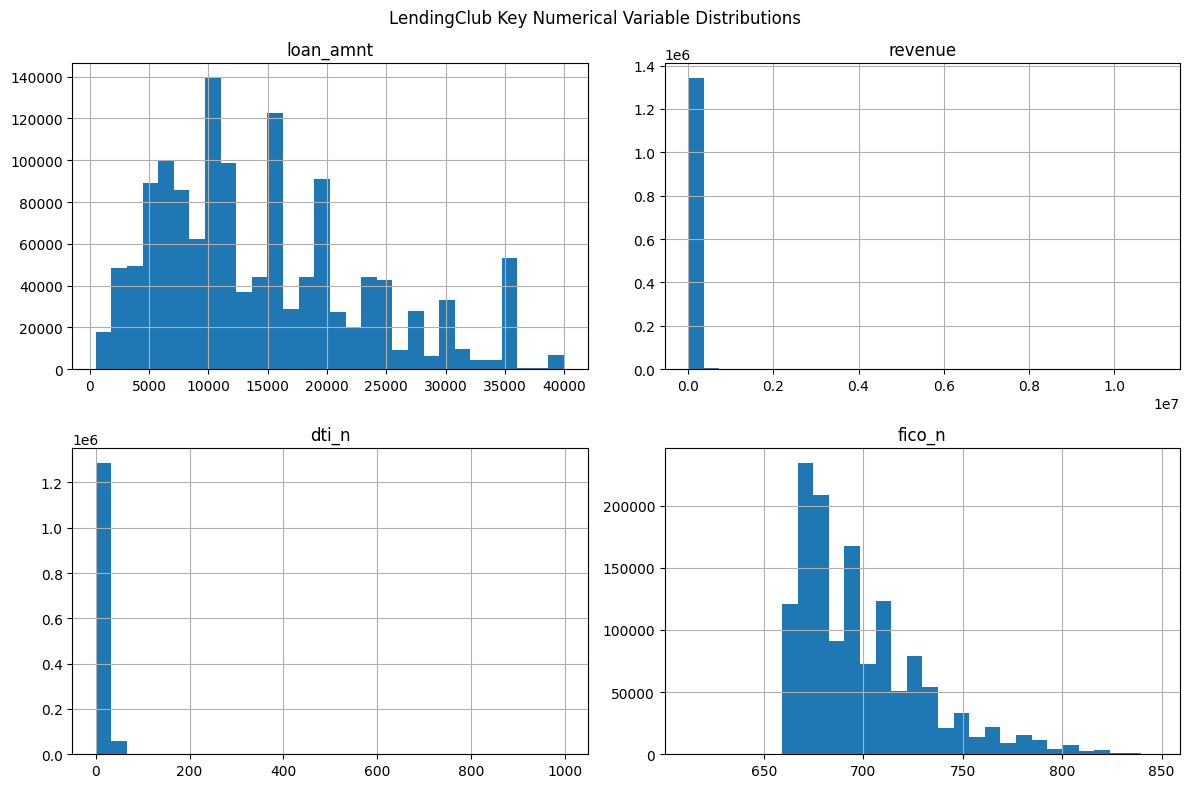

In [9]:
# Numerical Distribution - Lending Club

df[
    ['loan_amnt', 'revenue', 'dti_n', 'fico_n']
].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle('LendingClub Key Numerical Variable Distributions')
plt.tight_layout()
plt.show()

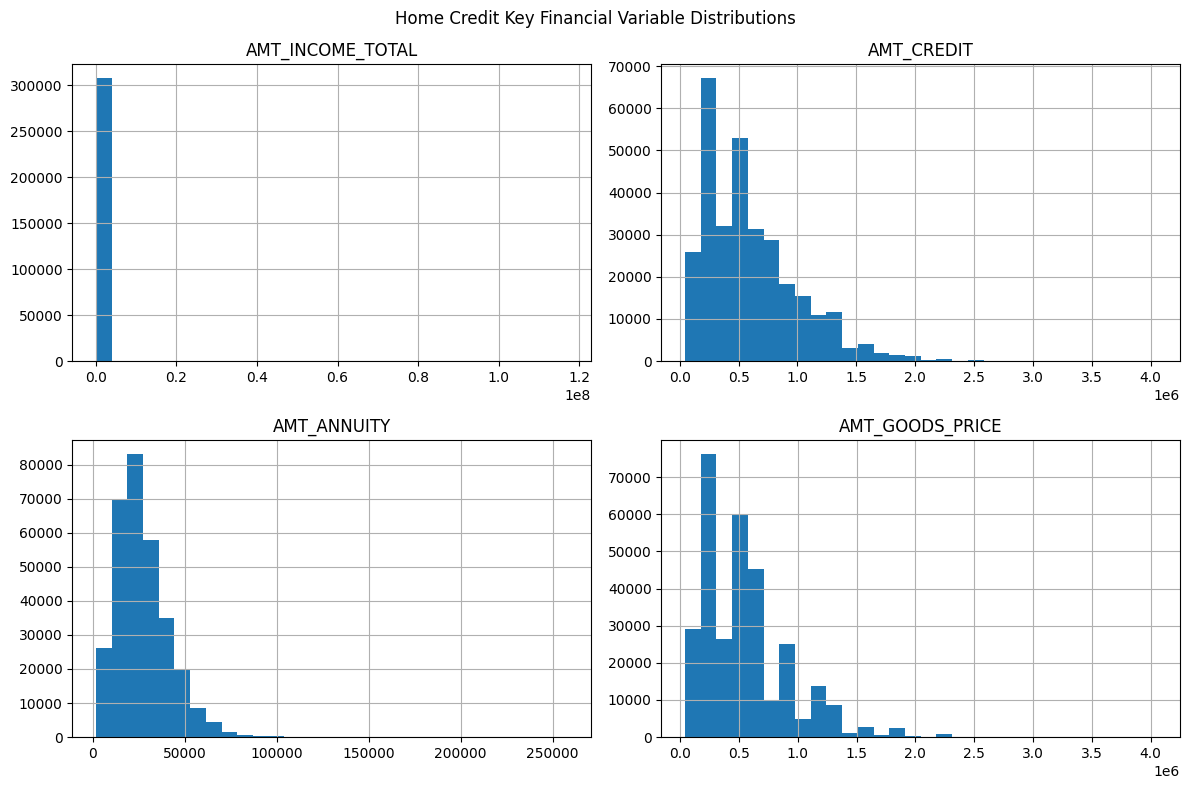

In [11]:
# Numerical Distribution - Home Credit (application_train.csv)

df_HC[
    [
        'AMT_INCOME_TOTAL',
        'AMT_CREDIT',
        'AMT_ANNUITY',
        'AMT_GOODS_PRICE'
    ]
].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle('Home Credit Key Financial Variable Distributions')
plt.tight_layout()
plt.show()
